# Treasure Hunt Game Notebook

## Read and Review Your Starter Code
The theme of this project is a popular treasure hunt game in which the player needs to find the treasure before the pirate does. While you will not be developing the entire game, you will write the part of the game that represents the intelligent agent, which is a pirate in this case. The pirate will try to find the optimal path to the treasure using deep Q-learning. 

---

**Name:** Michael Soto<br>
**Course:** CS 370 &mdash; Current/Emerging Trends in Computer Science<br>
**Assignment:** Project Two: Pirate Intelligent Agent<br>
**File:** `Soto_Michael_ProjectTwo.ipynb`<br>
**Date:** October 18, 2026

---

<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>TreasureHuntGame_starterCode.ipynb</b> file to complete your assignment. 
<br><br>
You have been provided with two Python classes and this notebook to help you with this assignment. The first class, <b>TreasureMaze.py</b>, represents the environment, which includes a maze object defined as a matrix. The second class, <b>GameExperience.py</b>, stores the episodes – that is, all the states that come in between the initial state and the terminal state. This is later used by the agent for learning by experience, called "exploration". This notebook shows how to play a game. Your task is to complete the deep Q-learning implementation in the qtrain() function for which a skeleton implementation has been provided. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
<b>NOTE: </b>The code block you will need to complete will have <b>#TODO</b> as a header.
<br> First, read and review the next few code and instruction blocks to understand the code that you have been given.</div>

<div class="alert alert-block alert-warning" style="color: #333333;">
<b>Installations</b> The following command will install the necessary Python libraries to necessary to run this application. If you see a "[notice] A new release of pip is available: 23.1.2 -> 25.2" at the end of the installation, you may disregard that statement. 
</div>

In [1]:
!pip install -r requirements.txt


[notice] A new release of pip is available: 24.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


<h2>Tensorflow CPU Acceleration Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
    <b>Example messages:</b>
    <ul>
        <li>oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders</li>
        <li>WARNING: All log messages before absl::InitializeLog() is called are written to STDERR</li>
</div>

### Forcing CPU Execution

Codio trains without a GPU, as the red box above warns. The cell below makes that explicit before TensorFlow loads. It also switches off oneDNN's custom operations, the subject of the first notice quoted in that box, which reorder floating-point arithmetic; with them off, one seed replays one training run on a given machine. Same three settings as my Module Three and Five notebooks.

In [2]:
# These must be set before TensorFlow is imported, which the next code cell does.
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'   # CPU only, the hardware Codio provides anyway
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'   # one fixed order of floating-point operations
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'    # hide TensorFlow's informational messages

In [3]:
from __future__ import print_function
import os, sys, time, datetime, json, random
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import clone_model
from keras.models import Sequential
from keras.layers import Dense, Activation, PReLU
from keras.optimizers import SGD , Adam, RMSprop
import matplotlib.pyplot as plt
from TreasureMaze import TreasureMaze
from GameExperience import GameExperience
%matplotlib inline

2026-10-05 08:43:58.955935: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-10-05 08:43:58.976134: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-10-05 08:43:58.982222: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


### Recording the Environment

A number means little without the versions behind it. So this cell prints them, and its first line also keeps matplotlib from writing its own name into the metadata of every figure below, the supplied `show()` pictures included.

<div class="alert alert-block alert-warning" style="color:black;">
<b>Reading the pink output.</b> Pink text is standard error. It is not a failure; a real failure prints a red traceback and stops Run All. Three sources account for the pink blocks you may see: pip's notice about its own version at the install cell, which the yellow box above already mentions; TensorFlow's start-up messages about CUDA and the missing GPU, which the red boxes treat as ignorable; and one Keras warning when <code>build_model()</code> passes <code>input_shape</code> to its first layer. That last one is a style preference in Keras 3 rather than a defect, and the supplied function stays exactly as written.
</div>

In [4]:
# Keep matplotlib's name out of the metadata of every figure drawn from here on.
%config InlineBackend.print_figure_kwargs = {'bbox_inches': 'tight', 'metadata': {'Software': None}}
import platform
import keras

# The versions behind every number this notebook prints.
print(f"Python      {platform.python_version()}")
print(f"NumPy       {np.__version__}")
print(f"TensorFlow  {tf.__version__}")
print(f"Keras       {keras.__version__}")

Python      3.11.9
NumPy       1.26.4
TensorFlow  2.17.0
Keras       3.4.1


<h2> Maze Object Generation</h2>

<div class="alert alert-block alert-info" style="color:black;">
    <b>NOTE:</b>  The following code block contains an 8x8 matrix that will be used as a maze object:
</div>

In [5]:
maze = np.array([
    [ 1.,  0.,  1.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  0.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  0.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  0.,  0.,  0.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  1.,  1.]
])

<h2>Helper Functions and Global Variables</h2>

<div class="alert alert-block alert-info" style="color:black;">
This <b>show()</b> helper function allows a visual representation of the maze object:
</div>

In [6]:
def show(qmaze):
    plt.grid('on')
    nrows, ncols = qmaze.maze.shape
    ax = plt.gca()
    ax.set_xticks(np.arange(0.5, nrows, 1))
    ax.set_yticks(np.arange(0.5, ncols, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    canvas = np.copy(qmaze.maze)
    for row,col in qmaze.visited:
        canvas[row,col] = 0.6
    pirate_row, pirate_col, _ = qmaze.state
    canvas[pirate_row, pirate_col] = 0.3   # pirate cell
    canvas[nrows-1, ncols-1] = 0.9 # treasure cell
    img = plt.imshow(canvas, interpolation='none', cmap='gray')
    return img

The <b>pirate agent</b> can move in four directions: left, right, up, and down. 

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note:</b> While the agent primarily learns by experience through exploitation, often, the agent can choose to explore the environment to find previously undiscovered paths. This is called "exploration" and is defined by epsilon. This value is the <b>EXPLORATION</b> values from the Cartpole assignment. The hyperparameters are provided here and used in the <b>qtrain()</b> method. 
You are encouraged to try various values for the exploration factor and see how the algorithm performs.
</div>

In [7]:
LEFT = 0
UP = 1
RIGHT = 2
DOWN = 3


# Exploration factor
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995
patience = 10

# Actions dictionary
actions_dict = {
    LEFT: 'left',
    UP: 'up',
    RIGHT: 'right',
    DOWN: 'down',
}

num_actions = len(actions_dict)


The sample code block and output below show creating a maze object and performing one action (DOWN), which returns the reward. The resulting updated environment is visualized.

reward= -0.04


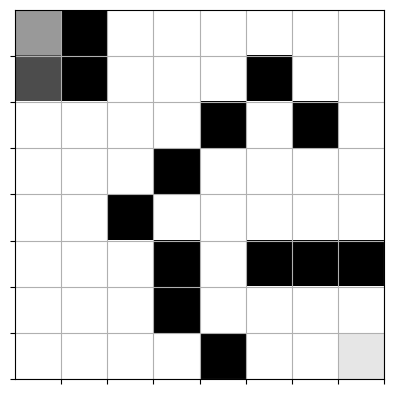

In [8]:
qmaze = TreasureMaze(maze)
canvas, reward, game_over = qmaze.act(DOWN)
print("reward=", reward)
show(qmaze)

<div class="alert alert-block alert-warning" style="color:black;">
    <b>NOTE:</b> This <b>play_game()</b> function simulates a full game based on the provided trained model. The other parameters include the TreasureMaze object, the starting position of the pirate and max amount of steps to make sure the code does not get stuck in a loop.
</div>

In [9]:
def play_game(model, qmaze, pirate_cell, max_steps=None):
    qmaze.reset(pirate_cell)
    envstate = qmaze.observe()
    steps = 0
    if max_steps is None:
        max_steps = qmaze.maze.size * 4  # safety cutoff

    while steps < max_steps:
        state = np.asarray(envstate, dtype=np.float32)
        if state.ndim == 1:
            state = np.expand_dims(state, axis=0)

        q_values = model(state, training=False).numpy()
        action = np.argmax(q_values[0])

        envstate, reward, game_status = qmaze.act(action)
        steps += 1

        if game_status == 'win':
            return True
        elif game_status == 'lose':
            return False

    return False  # timed out with no result

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
    This <b>completion_check()</b> function helps you to determine whether the pirate can win any game at all. If your maze is not well designed, the pirate may not win any game at all. In this case, your training would not yield any result. The provided maze in this notebook ensures that there is a path to win and you can run this method to check.
</div>

In [10]:
def completion_check(model, maze_or_qmaze, max_steps=None):
    # Accept either raw numpy maze or TreasureMaze instance
    if isinstance(maze_or_qmaze, TreasureMaze):
        qmaze = maze_or_qmaze
    else:
        qmaze = TreasureMaze(maze_or_qmaze)

    for cell in qmaze.free_cells:
        if not qmaze.valid_actions(cell):
            continue
        if not play_game(model, qmaze, cell, max_steps=max_steps):
            return False
    return True

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
</b>The <b>build_model()</b> function in the block below will build the neural network model. Review the code and note the number of layers, as well as the activation, optimizer, and loss functions that are used to train the model.
</div>

In [11]:
def build_model(maze):
    model = Sequential()
    model.add(Dense(maze.size, input_shape=(maze.size,)))
    model.add(PReLU())
    model.add(Dense(maze.size))
    model.add(PReLU())
    model.add(Dense(num_actions))
    model.compile(optimizer='adam', loss='mse')
    return model

<div class="alert alert-block alert-warning" style="color:black;">
    <b>Note:</b>
    This <b>train_step()</b> helper function in the block below is used to help predict Q-values (quality values) in the current modelto see how good each action is in a given state and improve the Q-network by reducing the gap between what is predicted and what should have been predicted. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
If you're interested in reading up on the <i>@tf.function</i>, which is a decorator for Tensorflow to run this code into a TensorFlow computation graph, please refer to this link: <a href="https://www.tensorflow.org/guide/intro_to_graphs">https://www.tensorflow.org/guide/intro_to_graphs</a>
</div>


<h2>Tensorflow GPU Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
    You will see a <b>warning in red</b> "INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.". This is simply coming from <b>Tensorflow skipping using GPU for this assignment.</b>  
</div>

In [12]:
loss_fn = tf.keras.losses.MeanSquaredError()
optimizer = tf.keras.optimizers.Adam()

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        q_values = model(x, training=True)
        loss = loss_fn(y, q_values)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

2026-10-05 08:44:02.363247: E external/local_xla/xla/stream_executor/cuda/cuda_driver.cc:266] failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


# #TODO: Complete the Q-Training Algorithm Code Block

<div class="alert alert-block alert-info" style="color:black;">
    This is your deep Q-learning implementation. The goal of your deep Q-learning implementation is to find the best possible navigation sequence that results in reaching the treasure cell while maximizing the reward. In your implementation, you need to determine the optimal number of epochs to achieve a 100% win rate.
</div>
    <b>Pseudocode:</b>
    <br>
    For each epoch:
        Reset the environment at a random starting cell
        agent_cell = randomly select a free cell
        <br>
        <b>Hint:</b> Review the reset method in the TreasureMaze.py class.
    
        Set the initial environment state
        env_state should reference the environment's current state
        Hint: Review the observe method in the TreasureMaze.py class.

        While game status is not game over:
           previous_envstate = env_state
            Decide on an action:
                - If possible, take a random valid exploration action and 
                  randomly choose action (left, right, up, down)
                  and assign it to an action variable
                - Else, pick the best exploitation action from the model and assign it to an action variable
                  Hint: Review the predict method in the GameExperience.py class.
    
           Retrieve the values below from the act() method.
           env_state, reward, game_status = qmaze.act(action)
           Hint: Review the act method in the TreasureMaze.py class.
    
            Track the wins and losses from the game_status using win_history 
         
           Store the episode below in the Experience replay object
           episode = [previous_envstate, action, reward, envstate, game_status]
           Hint: Review the remember method in the GameExperience.py class.
        
           Train neural network model and evaluate loss
           Hint: Call GameExperience.get_data to retrieve training data (input and target) 
           and pass to the train_step method and assign it to batch_loss and append to the loss variable
        
      If the win rate is above the threshold and your model passes the completion check, that would be your epoch.

Note: A 100% win rate <b>DOES NOT EXPLICITLY MEAN</b> that you have solved the maze. It simply indicates that during the last evaluation, the pirate <i>happened</i> to get to the treasure. Be sure to utilise the <b>completion_check()</b> function to validate your pirate found the treasure at every starting point and consistently! 

<b> You will need to complete the section starting with #START_HERE. Please use the pseudocode above as guidance. </b>


---

## My Q-Training Implementation

`qtrain()` plays one complete game per epoch from a random free cell and learns after every move. Each move goes into replay memory, a random minibatch comes back out, and the supplied `train_step()` takes one gradient step toward the Bellman targets; every fifty gradient steps, the target network gets a fresh copy of the online weights. Training ends at the first epoch where the last 32 games were all wins and `completion_check()` confirms a win from every free cell.

### What changed since the milestone

The learning algorithm is still the milestone's, move for move, though not for want of trying to change it. Ten seeds confirm it: on my own computer, each stopped at exactly the epoch it reached in the milestone. What changed is what the notebook measures, and what it has tested.

- **The milestone feedback, tested rather than assumed.** My instructor suggested updating the network on batches of stored moves instead of after each one. Every update here already trains on a batch drawn from replay memory. The open question was how often. Two less frequent cadences ran against the milestone's under a rule I froze first, and neither earned a place; the evidence follows `ReplayLearner` below.
- **Exploration is counted.** An `Explorer` now makes every move choice and tallies the random ones, so the training log ends with the share of moves that explored: the number the design defense needs when it names the right balance between exploring and exploiting.
- **Where the training time goes, measured.** The module asks for an agent that runs more efficiently, so I timed every piece of one run on my own computer. Most of that time was not mine to change. The supplied `get_data()` took 56% of it, repeated calls to `completion_check()` 17%, choosing greedy moves 13%, and the supplied `train_step()` 12%. That leaves two levers: how many moves training needs, which depends on exploration, and how many of those moves trigger a gradient step, since `get_data()` and `train_step()` run once per step. The feedback pointed at the second; I tested both.
- **The exploration schedule was tested, not assumed.** Before training anything, I froze five predictions and a decision rule, then trained five schedules on five practice seeds. The supplied schedule survived. The evidence, misses included, sits in the seeding section below.
- **A Q-table trains beside the network**, under the same rules and through the same game loop. Why? To show what the network buys, and what it costs.
- **A sixth decision the starter made for me (D6, below).** The observation hides the visited cells that decide part of the reward.

### What the supplied code decided for me

| | What the starter does | What I did |
|---|---|---|
| D1 | The pseudocode stores `game_status` in each episode, but `get_data()` tests it with `if done:`, and Python treats every non-empty string as true, `'not_over'` included. | Stored `is_terminal(game_status)`, a real boolean. A code cell near the end shows what the string would have done. |
| D2 | `target_update_freq` is passed in, yet the skeleton never uses it or says whether it counts games or gradient steps. | `TargetSync` counts gradient steps. A game can last one move or more than a hundred, so counting games refreshes the target at a ragged rate. For the milestone, counting steps reached the stopping rule for all ten seeds I tried on my own computer; counting games missed it for one seed in five within 1,000 epochs. |
| D3 | The specification prices a move into a wall at -0.75 and a move off the edge at -0.8 (Southern New Hampshire University, n.d.-a, "Agent Specifications" section). In `TreasureMaze.py`, an invalid move leaves the pirate in the cell it has just marked as visited, so the move is scored as a revisit: -0.25. | Nothing. The `.py` files are off limits, and a blocked move still costs more than a step onto a new cell (-0.04), so the incentive points the right way. |
| D4 | A game is lost once its total reward falls below `min_reward`, minus half the number of cells in the maze. | A loss is a budget running out, not a place in the maze, so its target still looks one move ahead; only a win is terminal (Farama Foundation, n.d., "Truncation" section). |
| D5 | `train_step()` trains whatever the global name `model` refers to when it first runs. | Nothing to change: the supplied training cell binds `model` to the same network `qtrain()` receives. |
| D6 | `observe()` erases the visited marks before handing the maze to the network, yet `get_reward()` charges -0.25 for stepping onto a visited cell and -0.04 for a fresh one. | Nothing in the code, but it shapes what can be learned. Two moves that look identical to the network can earn different rewards, so each Q-value averages over histories the network cannot see. In random walks on my own computer, 130 of the 132 (cell, move) pairs that occurred were rewarded both ways. A shortest route never revisits a cell, so the best route is still a choice of one move per cell; what the hidden history blurs is the values learned along the way. |

### Where each pseudocode step lives

| Pseudocode step | Where it happens |
|---|---|
| Reset at a randomly selected free cell | `play_training_game()`: `qmaze.reset(random.choice(qmaze.free_cells))` |
| Set the initial environment state | `play_training_game()`: `qmaze.observe()` |
| Decide on an action, exploring or exploiting | `Explorer.choose()`, which also counts the random choices |
| `envstate, reward, game_status = qmaze.act(action)` | `play_training_game()` |
| Track wins and losses in `win_history` | `qtrain()`, from the flag each game returns |
| Store the episode in experience replay | `ReplayLearner`: `experience.remember(...)` |
| Train on `get_data()` and record the batch loss | `ReplayLearner`: `get_data()` into the supplied `train_step()` |
| Keep the target network in step | `TargetSync`, called by `ReplayLearner` after every gradient step |
| Stop on a full win rate and a passing completion check | `qtrain()`, the supplied lines, unchanged |

### Deciding each move

`Explorer.choose()` is epsilon-greedy. With probability epsilon it explores, drawing at random from `valid_actions()`, so an exploratory move never walks into a wall; otherwise it exploits, taking the move whose Q-value is highest. Before returning, it notes which kind of move it made, one tally per game. That note is the only thing added to the milestone's `choose_action()`, and it draws no extra random numbers, so the seed still replays the same run.

Why a class now? Counting needs a memory that outlives each call, and a class is where such memory belongs. `summary()` turns the tallies into the last line of the training log: the share of all training moves that were random, followed by the same share over the first 50 games and over the last 50.

In [13]:
class Explorer:
    """Chooses each move epsilon-greedily and keeps count of how often it explored."""

    def __init__(self):
        """No games yet; each game adds an [explored, exploited] tally of its moves."""
        self.tallies = []
        self.seconds = None                              # set by the trainer when training ends

    def new_game(self):
        """Opens the tally for the game about to start."""
        self.tallies.append([0, 0])

    def choose(self, qmaze, q_values, envstate, epsilon):
        """A random valid move with probability epsilon, else the move with the highest Q-value."""
        valid_actions = qmaze.valid_actions()
        explore = bool(valid_actions) and random.random() < epsilon
        self.tallies[-1][0 if explore else 1] += 1       # count this move as explored or exploited
        if explore:
            return random.choice(valid_actions)          # explore: any move onto a free cell
        return int(np.argmax(q_values(envstate)))        # exploit: the highest Q-value

    def share(self, games=slice(None)):
        """The fraction of moves that explored, over all games or the slice given."""
        explored, exploited = np.sum(self.tallies[games], axis=0)
        return explored / (explored + exploited)

    def summary(self, window=50):
        """One line: the explored share overall, over the first `window` games, and the last."""
        moves = int(np.sum(self.tallies))
        return (f"Exploration: {self.share():.1%} of {moves:,} training moves were random; "
                f"{self.share(slice(None, window)):.1%} in the first {window} games and "
                f"{self.share(slice(-window, None)):.1%} in the last {window}.")

### Learning from replayed moves

`ReplayLearner` is the network's lesson from one move. It stores the move in replay memory and asks `GameExperience.get_data()` for a random minibatch whose targets are the Bellman values: the reward, plus 0.95 times the best Q-value of the next state as the target network sees it, unless the move ended the game. The batch goes to the supplied `train_step()`, and `TargetSync` counts the step. Drawing stored moves in random order reduces the correlation between consecutive training examples, which is why replay memory exists at all (Beysolow, 2019, "Deep Q Learning" section).

`TargetSync` holds the target network still between copies. In the same section, Beysolow (2019) describes the target network as sharing the Q network's weights but updated after it; here it trails the online network by at most fifty updates, so the targets stay put while the network chases them.

In [14]:
class TargetSync:
    """Copies the online network's weights into the target network every `every` updates.

    Between copies the target network stays fixed, so the Bellman targets it produces do not
    shift with every gradient step taken by the network they are training.
    """

    def __init__(self, model, target_model, every):
        """Remembers both networks and how many gradient steps to wait between copies."""
        self.model, self.target_model, self.every = model, target_model, every
        self.updates = 0                                  # gradient steps taken so far

    def after_update(self):
        """Counts one gradient step and refreshes the target network when a copy is due."""
        self.updates += 1
        if self.updates % self.every == 0:
            self.target_model.set_weights(self.model.get_weights())


class ReplayLearner:
    """The network's lesson from one move: store it, replay a minibatch, keep the target in step."""

    def __init__(self, experience, data_size, sync):
        """Holds the replay memory, the minibatch size, and the target network's schedule."""
        self.experience, self.data_size, self.sync = experience, data_size, sync

    def __call__(self, episode):
        """Stores one move, takes one gradient step on a random minibatch, returns its loss."""
        self.experience.remember(episode)                # store the episode in experience replay
        inputs, targets = self.experience.get_data(self.data_size)   # targets: target network
        # The supplied train_step updates the global `model`, the network passed to qtrain below.
        loss = float(train_step(inputs, targets))
        self.sync.after_update()
        return loss

### Responding to the milestone feedback

My instructor's comment on the milestone was to "consider using a replay buffer and performing model updates on batches of stored experiences instead of updating after each episode." Half of that was already here, because the starter supplies it: `GameExperience` is the replay buffer, and every update above trains on a random batch of 32 stored moves rather than on the latest move alone. The other half is a question of cadence. `GameExperience` calls each stored move an episode, and the pseudocode takes a gradient step after every one, as the textbook's own catch example does (Gulli & Pal, 2017, p. 280). DeepMind's network did not; it selected four actions between successive updates (Mnih et al., 2015, Extended Data Table 1). Updating less often should also be cheaper. `get_data()` and `train_step()` run once per update, and together they took more than two thirds of the training time I measured.

So I tested it the way I tested exploration. Before any run, I froze four predictions and a rule (`PREDICTIONS_feedback.md`): a new cadence replaces the milestone's only if it meets the stopping rule on all five practice seeds, keeps its median shortest routes within one of the milestone's, and cuts the median training time by at least 15%. Both candidates still store every move. One takes a gradient step every fourth move on the usual batch of 32; the other, every fourth move on a batch of 128, which replays as many stored moves per move as the milestone does in a quarter of the updates, and all three ran side by side on my own computer, on the same practice seeds the exploration test used.

| Gradient step | Batch | Met the rule | Stopping epoch: median (range) | Training seconds (median) | Shortest routes (median, of 50) | Gradient steps (median) |
|---|---|---|---|---|---|---|
| After every move (milestone) | 32 | 5 of 5 | 330 (243 to 415) | 110 | 49 | 23,339 |
| Every 4th move | 32 | 0 of 5 | none within 1,000 | 168 | 17 | 24,888 |
| Every 4th move | 128 | 5 of 5 | 649 (571 to 749) | 105 | 46 | 11,712 |

Neither candidate qualified. The milestone's cadence stays, so the code above is unchanged. The batch of 32 every fourth move never met the rule; after 1,000 games it still won from no more than 21 of the 50 cells. The batch of 128 met it on every seed but needed about twice the games, so the time it saved on each move went into extra moves (a median of 105 seconds against 110), and it left three fewer cells on a shortest route. One of the three predictions I could score held. The first candidate did need more games than the milestone, but I had expected the second to be adopted, and to vary less from seed to seed; its stopping epochs spread over 178 epochs, the milestone's over 172.

Was the target network to blame? `TargetSync` counts gradient steps (D2), so both candidates refreshed it every 200 moves instead of every 50. After the decision, and outside the frozen rule, I reran them with a refresh every 13 gradient steps, close to the milestone's pace in moves. The batch of 128 then stopped at a median epoch of 568 instead of 649, and the batch of 32 met the rule on one seed in five. The slower target explains about a quarter of the gap. The rest is the cadence itself. Per update, the big batches did more, meeting the rule after a median of 11,712 gradient steps against the milestone's 23,339. Per game, they did less. With the faster refresh, the batch of 128 came closest to the steadiness my instructor described, its stopping epochs falling within 63 of each other, the narrowest spread of any version that met the rule on all five seeds. It still needed far more games than the milestone, so the replay buffer stays exactly as the milestone used it: every move stored, and a random batch of 32 replayed after each one.

### One training game

`play_training_game()` is the pseudocode's inner loop, nearly line for line, with one change of shape since the milestone: it no longer knows what kind of learner it trains. It takes two functions instead. `q_values` rates the four moves in a state, and `learn` absorbs one stored move and returns a loss. For the network, those are `GameExperience.predict()` and a `ReplayLearner`; for the Q-table near the end of this notebook, two methods of the table. One loop, two learners, no copied code. That is my instructor's advice about reusable functions, applied where it pays most.

The loop returns the game's mean loss, its number of moves, and whether the pirate won. `qtrain()` prints the first two as Loss and Episodes (`GameExperience` calls each stored move an episode, and the supplied print line kept the name), and the third feeds `win_history`, from which the supplied lines compute the win rate that decides when training stops. `is_terminal()` is one line long and settles D1 and D4 at once.

In [15]:
def is_terminal(game_status):
    """The done flag stored with each move, as a real boolean.

    Only a win ends the task. A loss means the reward budget ran out, which is a cutoff
    rather than a state of the maze, so its target still looks one move ahead.
    """
    return game_status == 'win'


def play_training_game(qmaze, explorer, epsilon, q_values, learn):
    """Plays one game from a random free cell, learning after every move.

    `q_values` rates the moves in a state and `learn` absorbs one stored move, so the deep
    Q-network and the Q-table later in this notebook train through this same loop. Returns
    the game's mean loss, its number of moves, and whether the pirate won.
    """
    qmaze.reset(random.choice(qmaze.free_cells))         # reset at a randomly selected free cell
    envstate = qmaze.observe()                           # the maze flattened, pirate marked
    explorer.new_game()                                  # a fresh tally of random and best moves
    losses, game_status = [], 'not_over'
    while game_status == 'not_over':
        previous_envstate = envstate
        action = explorer.choose(qmaze, q_values, previous_envstate, epsilon)
        envstate, reward, game_status = qmaze.act(action)
        # Store the move with a boolean done flag (not the status string) and learn from it.
        episode = [previous_envstate, action, reward, envstate, is_terminal(game_status)]
        losses.append(learn(episode))
    return float(np.mean(losses)), len(losses), game_status == 'win'

In [16]:
def qtrain(model, maze, **opt):
    """Trains `model` by deep Q-learning until the pirate can win from every free cell.

    Each epoch is one game. Training stops at the first epoch whose recent win rate is 100%
    and whose greedy policy passes completion_check, or after n_epoch epochs.
    """
    # exploration factor
    global epsilon 
    
    # Number of epochs
    n_epoch = opt.get('n_epoch', 15000)
    
    # Maximum meory to store episodes
    max_memory = opt.get('max_memory', 1000)
    
    # Maximum data size for training
    data_size = opt.get('data_size', 50)
    
    # Frequency of target network updates
    target_update_freq = opt.get('target_update_freq', 50)
    
    # Start time
    start_time = datetime.datetime.now()
    
    # Construct environment/game from numpy array: maze (see argument above)
    qmaze = TreasureMaze(maze)
    
    # Target Network to better guide training
    target_model = clone_model(model)
    target_model.set_weights(model.get_weights())
    
    # Initialize experience replay object
    experience = GameExperience(model, target_model, max_memory=max_memory)

    win_history = [] # history of win/lose game
    hsize = qmaze.maze.size // 2 #history window size
    win_rate = 0.0
    
    # =============START_HERE================
    # Refresh the target network every `target_update_freq` gradient steps.
    sync = TargetSync(model, target_model, every=target_update_freq)
    learn = ReplayLearner(experience, data_size, sync)   # store, replay, train, sync
    global explorer                                      # kept for the comparison cells below
    explorer = Explorer()                                # chooses moves, counts the random ones
    for epoch in range(n_epoch):  
        # Play one game from a random free cell, training after every move. GameExperience
        # calls each stored move an "episode", so n_episodes counts this game's moves.
        loss, n_episodes, won = play_training_game(qmaze, explorer, epsilon, experience.predict, learn)
        win_history.append(1 if won else 0)              # track the win (1) or loss (0)

        # Win rate over last hsize steps 
        win_rate = sum(win_history[-hsize:]) / hsize if len(win_history) >= hsize else 0.0

        # Print the epoch, loss, episode, win count, win rate, and time for each epoch
        dt = datetime.datetime.now() - start_time
        t = format_time(dt.total_seconds())
        print("Epoch: {:03d}/{:d} | Loss: {:.4f} | Episodes: {:d} | Win count: {:d} | Win rate: {:.3f} | time: {}".format(
            epoch, n_epoch-1, loss, n_episodes, sum(win_history), win_rate, t))

        # Check if training has exhausted all free cells and if in all
        # cases the agent won
        if win_rate > 0.9:
            epsilon = 0.05
        else:
            epsilon = max(epsilon * epsilon_decay, epsilon_min)
    
        if win_rate >= 0.999 and completion_check(model, maze):
            print(f"Reached 100% win rate at epoch {epoch}")
            break

    total_time = format_time((datetime.datetime.now() - start_time).total_seconds())
    print("Training complete in:", total_time)
    explorer.seconds = (datetime.datetime.now() - start_time).total_seconds()
    print(explorer.summary())                            # how much of training was exploration


# This is a small utility for printing readable time strings:
def format_time(seconds):
    if seconds < 400:
        s = float(seconds)
        return "%.1f seconds" % (s,)
    elif seconds < 4000:
        m = seconds / 60.0
        return "%.2f minutes" % (m,)
    else:
        h = seconds / 3600.0
        return "%.2f hours" % (h,)

## Test Your Model

Now we will start testing the deep Q-learning implementation. To begin, select **Cell**, then **Run All** from the menu bar. This will run your notebook. As it runs, you should see output begin to appear beneath the next few cells. The code below creates an <b>instance</b> of TreasureMaze. This does not show your actual training done.

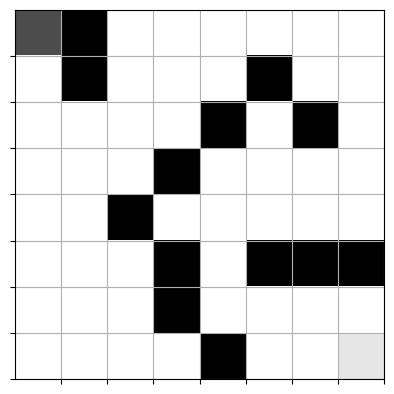

In [17]:
qmaze = TreasureMaze(maze)
show(qmaze)

In the next code block, you will build your model using the <b>build_model</b> function and train it using deep Q-learning. Note: This step takes several minutes to fully run.



<div class="alert alert-block alert-danger" style="color: #333333;">
  <b>WARNING</b>  If you did not attempt the assignment, the code <b>will</b> error out at this section.
 </div>

### Seeding for Reproducibility

One call seeds Python's `random` (start cells and exploration), NumPy (replay sampling) and TensorFlow (the initial weights). On a given machine, Run All then replays the same training run every time. I checked. Running the notebook twice on my own computer produced two training logs identical line for line, apart from the timings. Another machine may round differently in the last digits, and over many games that is enough to move the stopping epoch, which is why every figure worth quoting in this notebook comes from the code's own printout rather than from my sentences.

Reference: [keras.utils.set_random_seed](https://keras.io/api/utils/python_utils/#setrandomseed-function)

### Choosing how much to explore

The starter invites trying "various values for the exploration factor," so I did, but only after writing down what I expected and how I would decide (`PREDICTIONS.md`, frozen with a hash before any of these runs). Each schedule is a first epsilon, a decay per game and a floor; the supplied lines of `qtrain()` still drop epsilon to 0.05 once the win rate passes 0.9. All five trained on the same five practice seeds on my own computer, seeds this notebook never uses.

| Schedule (first, decay, floor) | Random moves | Stopping epoch: median (range) | Shortest routes (median, of 50) | Met the rule |
|---|---|---|---|---|
| Supplied (1.0, 0.995, 0.05) | 55 to 66% | 330 (243 to 415) | 49 | 5 of 5 |
| Faster decay (1.0, 0.99, 0.05) | 29 to 44% | 366 (288 to 581) | 48 | 5 of 5 |
| Slower decay (1.0, 0.998, 0.05) | 71 to 81% | 292 (237 to 425) | 48 | 5 of 5 |
| Constant 10% (0.1, 1.0, 0.1) | 9 to 10% | 322 (182 to 526) | 46 | 5 of 5 |
| None until winning (0, 1.0, 0) | 0 to 1% | 402 (257 to 519) | 48 | 5 of 5 |

Three of my five predictions about exploration missed. I expected a faster decay to train faster and a slower one to train slower, and the reverse happened; I expected no exploration at all to fail, and it never did. The start of each game explains the last surprise. Every game begins at a randomly chosen free cell, so the pirate's experience spreads across the maze even when every move it makes is greedy, and the revisit penalty keeps a greedy pirate stepping onto fresh cells. In this maze, exploration changes how fast the pirate learns, not whether it learns.

It changes speed by less than the table suggests, though. Within any one schedule, the stopping epoch moved by at least 172 epochs from seed to seed, more than the 110 that separate the fastest median from the slowest. Seeds matter more than schedules here. So my rule, fixed in advance, demanded a 15% cut in the median before anything replaced the supplied schedule. The best candidate, the slower decay, managed about 12%. The supplied schedule stays, and the cell below prints it.

In [18]:
SEED = 1671                              # the seed used in Modules Two, Three and Five

tf.keras.utils.set_random_seed(SEED)     # seeds Python's random, NumPy and TensorFlow together
# The exploration schedule qtrain starts from, saved before training changes epsilon.
SCHEDULE = (epsilon, epsilon_decay, epsilon_min)          # (first epsilon, decay per game, floor)
print(f"Seeded with {SEED}. Epsilon starts at {epsilon}, shrinks by a factor of {epsilon_decay} "
      f"per game, and stops at {epsilon_min}.")

Seeded with 1671. Epsilon starts at 1.0, shrinks by a factor of 0.995 per game, and stops at 0.05.


In [19]:
model = build_model(maze)
qtrain(model, maze, n_epoch=1000, max_memory=8*maze.size, data_size=32, target_update_freq=50)

/home/codio/.pyenv/versions/3.11.9/lib/python3.11/site-packages/keras/src/layers/core/dense.py:87: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch: 000/999 | Loss: 0.0074 | Episodes: 85 | Win count: 1 | Win rate: 0.000 | time: 1.8 seconds
Epoch: 001/999 | Loss: 0.0049 | Episodes: 1 | Win count: 2 | Win rate: 0.000 | time: 1.8 seconds
Epoch: 002/999 | Loss: 0.0058 | Episodes: 148 | Win count: 2 | Win rate: 0.000 | time: 3.4 seconds
Epoch: 003/999 | Loss: 0.0061 | Episodes: 150 | Win count: 2 | Win rate: 0.000 | time: 5.1 seconds
Epoch: 004/999 | Loss: 0.0050 | Episodes: 145 | Win count: 2 | Win rate: 0.000 | time: 6.7 seconds
Epoch: 005/999 | Loss: 0.0038 | Episodes: 142 | Win count: 2 | Win rate: 0.000 | time: 8.3 seconds
Epoch: 006/999 | Loss: 0.0018 | Episodes: 148 | Win count: 2 | Win rate: 0.000 | time: 10.0 seconds
Epoch: 007/999 | Loss: 0.0018 | Episodes: 150 | Win count: 2 | Win rate: 0.000 | time: 11.7 seconds
Epoch: 008/999 | Loss: 0.0019 | Episodes: 142 | Win count: 2 | Win rate: 0.000 | time: 13.3 seconds
Epoch: 009/999 | Loss: 0.0018 | Episodes: 145 | Win count: 2 | Win rate: 0.000 | time: 14.9 seconds
Epoch: 01

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b> This cell will check to see if the model passes the completion check. Note: This could take several minutes.
</div>

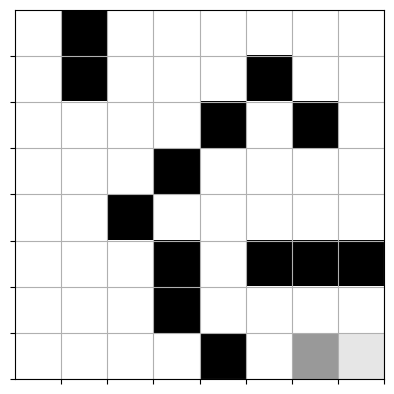

In [20]:
completion_check(model, qmaze)
show(qmaze)

This cell will test your model for one game. It will start the pirate at the top-left corner and run <b>play_game()</b>. The agent should find a path from the starting position to the target (treasure). The treasure is located in the bottom-right corner.

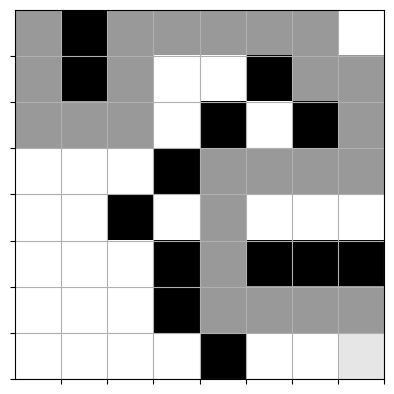

In [21]:
pirate_start = (0, 0)
play_game(model, qmaze, pirate_start)
show(qmaze)

---

## Verifying the Trained Pirate

First, the question of epochs. The training log above ends with this run's answer, `Reached 100% win rate at epoch N`. Epochs count from zero, so the run needed N + 1 games, and because training stops at the first epoch that meets the rule, that is the smallest number of epochs that satisfies it for this seed. It belongs to the run, not to the maze. On my own computer, the ten seeds I report on stopped at ten different epochs, none needing much more than half of the supplied 1,000.

The log's last line answers a different question: how much of the training was exploration. Its three percentages are this run's own record of the shift from exploring to exploiting, mostly random at the start and mostly greedy by the end, and the design defense builds on them.

The TODO box warns that a 100% win rate does not by itself mean the maze is solved; `completion_check()`, which plays a game from every free cell, is the supplied remedy, and this section keeps it while adding the one question the specification invites by asking for the best possible route to the treasure. Shortest route, or merely a route?

### The shortest possible route from every cell

A breadth-first search outward from the treasure labels every free cell with the fewest moves that can reach it. It depends on the maze alone. No training is involved, so the line it prints is the same on every machine: 50 starting cells, the farthest 28 moves from the treasure. That distance shapes the values the network has to learn. The treasure's reward, the only positive one, reaches that far corner only after being discounted by 0.95 at each step before the last, which leaves about a quarter of it, and once the -0.04 charged for every step along the way is counted, even the best first move from there is worth less than zero.

In [22]:
import collections

# Each action as a (row, column) step, keyed by the supplied action constants.
MOVES = {LEFT: (0, -1), UP: (-1, 0), RIGHT: (0, 1), DOWN: (1, 0)}


def is_free(maze, cell):
    """True if `cell` lies inside the maze and is not a wall."""
    row, col = cell
    return 0 <= row < maze.shape[0] and 0 <= col < maze.shape[1] and maze[row, col] == 1.0


def shortest_moves(maze, target):
    """Breadth-first search out from the target: the fewest moves from every free cell."""
    moves, frontier = {target: 0}, collections.deque([target])   # distance so far, cells to expand
    while frontier:
        row, col = frontier.popleft()                    # nearest unexpanded cell first
        for d_row, d_col in MOVES.values():
            cell = (row + d_row, col + d_col)
            if is_free(maze, cell) and cell not in moves:
                moves[cell] = moves[(row, col)] + 1       # one move farther than its neighbor
                frontier.append(cell)
    return moves


# Facts about the maze alone, identical on every machine because no training is involved.
fewest_moves = shortest_moves(maze, (maze.shape[0] - 1, maze.shape[1] - 1))   # from the treasure
print(f"{len(fewest_moves) - 1} free cells can reach the treasure; "
      f"the farthest is {max(fewest_moves.values())} moves away.")

50 free cells can reach the treasure; the farthest is 28 moves away.


### Replaying the pirate from each cell

`PolicyAudit` plays the trained network greedily, with no exploration and no learning, from every free cell, and it cuts each game off where `play_game()` does, at four moves per maze cell. Later it judges the Q-table too. `route_grid()` then draws the maze as text. Each free cell shows how many moves the pirate took from there; a star marks a cell where a shorter route exists, an x a cell where the pirate never arrived, # a wall, and T the treasure. `route_summary()` condenses the grid into two lines.

In [23]:
class PolicyAudit:
    """Plays the trained pirate greedily from every free cell and records each route."""

    def __init__(self, model, maze):
        """Keeps the trained network and the maze, and builds a private game to play in."""
        self.model, self.maze = model, maze
        self.qmaze = TreasureMaze(maze)                  # reset to each starting cell in turn

    def greedy_action(self, envstate):
        """The action the trained network rates highest in this state (no exploration)."""
        q_values = self.model(np.asarray(envstate, dtype=np.float32), training=False)
        return int(np.argmax(q_values[0]))

    def route_from(self, cell):
        """Plays one greedy game from `cell`; returns the cells visited and whether it won."""
        self.qmaze.reset(cell)
        envstate, route, status = self.qmaze.observe(), [cell], 'not_over'
        for _ in range(self.maze.size * 4):              # the same safety cutoff play_game uses
            envstate, _, status = self.qmaze.act(self.greedy_action(envstate))
            route.append(self.qmaze.state[:2])           # (row, col) after the move
            if status != 'not_over':
                break
        return route, status == 'win'

    def rows(self):
        """(cell, moves taken or None if the pirate failed, fewest possible) per free cell."""
        fewest = shortest_moves(self.maze, self.qmaze.target)
        table = []
        for cell in self.qmaze.free_cells:               # every legal starting cell
            route, won = self.route_from(cell)
            table.append((cell, len(route) - 1 if won else None, fewest.get(cell)))
        return table

In [24]:
def route_grid(rows, maze):
    """The maze as text: moves taken from each free cell, '*' where a shorter route exists."""
    grid = [['  #' if value == 0.0 else '   ' for value in line] for line in maze]
    grid[-1][-1] = '  T'                                 # the treasure
    for (row, col), taken, fewest in rows:
        if taken is None:
            grid[row][col] = '  x'                       # the pirate never reached the treasure
        else:
            grid[row][col] = f"{taken:>2}" + ('*' if taken > fewest else ' ')
    return '\n'.join(' '.join(line) for line in grid)


def route_summary(rows):
    """Two lines: how many cells win, how many by a shortest route, and the longest route."""
    wins = [row for row in rows if row[1] is not None]
    optimal = [row for row in wins if row[1] == row[2]]
    text = (f"{len(wins)} of {len(rows)} free cells reach the treasure, "
            f"{len(optimal)} of them by a shortest route.")
    if wins:                                             # name the longest winning route
        cell, taken, fewest = max(wins, key=lambda row: row[1])
        text += f"\nLongest route: {taken} moves from {cell}; the fewest possible is {fewest}."
    return text

### The result

Three parts, in order: the verdict of `completion_check()`, printed at last (the supplied cell above computes it but displays only the figure), the two-line summary, and the grid.

In [25]:
# Replay the trained pirate greedily from every free cell: no exploration and no learning.
audit_rows = PolicyAudit(model, maze).rows()

# The supplied cell above computes completion_check without displaying it, so show it here.
print("Completion check:", "passed" if completion_check(model, maze) else "FAILED")
print(route_summary(audit_rows))                         # the result in two lines
print()
print(route_grid(audit_rows, maze))                      # and cell by cell

Completion check: passed
50 of 50 free cells reach the treasure, 48 of them by a shortest route.
Longest route: 28 moves from (7, 1); the fewest possible is 26.

24    # 18  17  16  15  14  13 
23    # 19  18  17    # 13  12 
22  21  20  19    #  9    # 11 
23  22  23*   #  7   8   9  10 
24  23    #  7   6   7   8   9 
25  24  25    #  5    #   #   #
26  25  26    #  4   3   2   1 
27  28* 27  28    #  2   1    T


A star is not a failure. `completion_check()` asks only whether the pirate arrives, and a starred cell passes it. What a star records is subtler: when two routes differ by a move or two, their discounted values differ only slightly, and a single network ranking four actions in each of 50 cells with one shared set of weights can order a near-tie the wrong way. The stopping rule never looks at route length. Training ends as soon as that rule is met, stars or not; the closing notes explain why this notebook reports route length rather than enforcing it.

### The policy as a picture

D6 matters here too. Because the network sees only where the pirate stands, its policy is one fixed move per cell, drawn below as an arrow, and following the arrows from any cell traces exactly the route the grid above counted, wall bumps and detours included. An orange outline marks any cell whose route is longer than the shortest or never arrives. Its legend appears only then.

In [26]:
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle

# Walls, floor, arrows, a warning outline, and text: one color per job.
WALL, FLOOR, ARROW, FLAG, INK = '#52514e', '#fcfcfb', '#2a78d6', '#eb6834', '#0b0b0b'


def greedy_arrows(audit):
    """(x, y, dx, dy) for the greedy action in every free cell, in image coordinates."""
    arrows = []
    for row, col in audit.qmaze.free_cells:
        audit.qmaze.reset((row, col))                    # put the pirate on this cell
        d_row, d_col = MOVES[audit.greedy_action(audit.qmaze.observe())]
        arrows.append((col, row, d_col, d_row))          # x is the column, y the row
    return np.array(arrows, dtype=float).T


def style_maze_axes(ax, shape, title):
    """Cell borders in the floor color, no tick labels, and a left-aligned title."""
    ax.set_xticks(np.arange(-0.5, shape[1], 1), minor=True)
    ax.set_yticks(np.arange(-0.5, shape[0], 1), minor=True)
    ax.grid(which='minor', color=FLOOR, linewidth=2)     # a thin gap between cells
    ax.tick_params(which='both', length=0, labelbottom=False, labelleft=False)
    for spine in ax.spines.values():                     # a quiet outer edge instead of black
        spine.set_edgecolor(WALL)
    ax.set_title(title, loc='left', color=INK, fontsize=11)

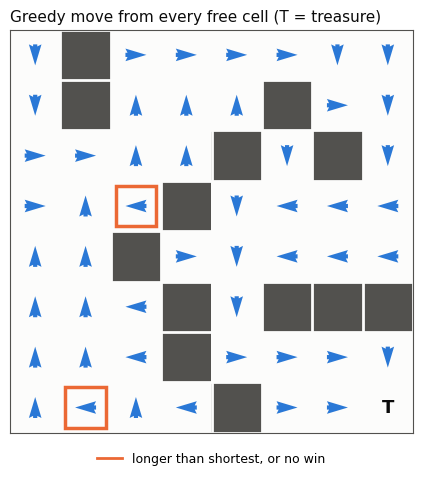

In [27]:
def plot_policy(audit, rows):
    """The maze with the trained pirate's chosen move drawn as an arrow in every free cell."""
    fig, ax = plt.subplots(figsize=(5.2, 5.4))
    ax.imshow(audit.maze, cmap=ListedColormap([WALL, FLOOR]), vmin=0, vmax=1)   # 0 wall, 1 floor
    ax.quiver(*greedy_arrows(audit), color=ARROW, angles='xy', scale_units='xy', scale=2.4,
              pivot='middle', width=0.012)             # each arrow centered in its cell
    flagged = [cell for cell, taken, fewest in rows if taken is None or taken > fewest]
    for row, col in flagged:                             # outline any cell that falls short,
        ax.add_patch(Rectangle((col - 0.4, row - 0.4), 0.8, 0.8, fill=False,  # inset so the
                               edgecolor=FLAG, linewidth=2.5, zorder=3))     # grid can't hide it
    if flagged:                                          # a legend only when something is flagged
        flag = Line2D([], [], color=FLAG, linewidth=2, label='longer than shortest, or no win')
        ax.legend(handles=[flag], loc='upper center', bbox_to_anchor=(0.5, -0.02),
                  frameon=False, fontsize=9)
    goal_row, goal_col = audit.qmaze.target
    ax.text(goal_col, goal_row, 'T', ha='center', va='center', color=INK,
            fontsize=13, fontweight='bold')
    style_maze_axes(ax, audit.maze.shape, 'Greedy move from every free cell (T = treasure)')
    return fig


# Draw the policy the network learned: one arrow per free cell, walls in dark gray.
plot_policy(PolicyAudit(model, maze), audit_rows)
plt.show()

One feature of the maze deserves a look here. The treasure sits in a pocket that joins the rest of the maze through a single free cell, so every winning route from outside the pocket squeezes through that one opening, and a wrong arrow there would break all of those starts at once.

### Why the stored done flag is a boolean

The pseudocode says to store `game_status` in each episode. Taken literally, that stores a string. `GameExperience.get_data()` then decides whether a move ended the game with `if done:`, and Python counts every non-empty string as true, so `'not_over'` would mark every ordinary move as the last one and collapse every target to the move's immediate reward. The cell below builds the target for one ordinary move both ways, using the trained network. Seeing beats describing.

In [28]:
def replay_target(model, transition):
    """The Bellman target GameExperience.get_data builds for one stored move."""
    probe = GameExperience(model, model, max_memory=1)   # a one-move memory, so the sample is fixed
    probe.remember(transition)
    _, targets = probe.get_data(batch_size=1)
    return targets[0, transition[1]]                     # the entry for the action taken


demo = TreasureMaze(maze)                  # a fresh game with the pirate at the top-left cell
before = demo.observe()
after, reward, status = demo.act(DOWN)     # one ordinary move that does not end the game
print(f"{'reward for the move alone:':<42}{reward:+.4f}")     # values line up below
for label, done in (("status string", status), ("boolean", is_terminal(status))):
    target = replay_target(model, [before, DOWN, reward, after, done])
    print(f"target with the {label:<13} {done!r:>10}: {target:+.4f}")

reward for the move alone:                -0.0400
target with the status string 'not_over': -0.0400
target with the boolean            False: -0.7834


With the string stored, the target is the reward and nothing more. With the boolean, it adds 0.95 times the best Q-value of the next cell, and that added term is what makes this deep Q-learning; without it, the network only learns to predict the next reward.

I expected the literal version to fail outright, and I was wrong. On my own computer it still passed the completion check for all three seeds I tried. Immediate rewards carry a signal of their own in this maze: a step onto a fresh cell costs -0.04 and a step back onto a visited one costs -0.25, so a network that predicts nothing beyond the next reward most likely still learns to keep moving away from where it has been, and in a maze this small that was enough. So the boolean does not rescue the pirate. It makes the training the algorithm the specification asks for.

---

## A Q-Table Beside the Network

The milestone closed on a question this section answers. The maze has 50 starting cells and four moves, so a table of 200 values could hold every Q-value the pirate needs; is a neural network worth having at all? The Module Five introduction warns that a Q-table becomes impractical as the numbers of states and actions grow (Southern New Hampshire University, n.d.-b, "Module Overview" section, para. 3), and Botvinick et al. (2019) draw the same line, a look-up table for "simple settings" and a parameterized function for richer ones (p. 409). Which side is this maze on? Only a test can say.

`QTable` is tabular Q-learning in a few lines. Its state is the pirate's cell, read from the very observation the network receives; D6 showed that the observation carries nothing else, so one row per cell loses no information the network had. The update is the textbook one: Q(s, a) moves a step of size alpha toward the same Bellman target `GameExperience` builds (Gulli & Pal, 2017, p. 268).

Two small touches let it reuse everything else. `predict()` and `learn()` are exactly the two functions `play_training_game()` expects, and `__call__()` answers like a Keras model, so the supplied `completion_check()` judges the table the same way it judges the network. `train_table()` then copies `qtrain()`'s rules. Same schedule, same 32-game window, same stopping test.

In [29]:
from TreasureMaze import pirate_mark            # the 0.5 that marks the pirate's cell


class QTable:
    """Tabular Q-learning: four Q-values for each maze cell, and no neural network.

    The observation marks nothing but the pirate's cell, so one row per cell holds everything
    the network could know about a state.
    """

    def __init__(self, maze, alpha, discount=0.95):
        """A row of zeros per cell; `alpha` is the step size, `discount` matches GameExperience."""
        self.q = np.zeros((maze.size, num_actions))
        self.alpha, self.discount = alpha, discount

    def predict(self, envstate):
        """The four Q-values of the pirate's cell, as a view into the table."""
        return self.q[int(np.argmax(np.ravel(envstate) == pirate_mark))]

    def __call__(self, states, training=False):
        """A model-style call, so the supplied completion_check can judge the table as well."""
        cells = np.argmax(np.asarray(states) == pirate_mark, axis=1)   # pirate's cell per row
        return tf.constant(self.q[cells])

    def learn(self, episode):
        """One Q-learning update toward the same Bellman target; returns the squared error."""
        state, action, reward, next_state, done = episode
        target = reward if done else reward + self.discount * np.max(self.predict(next_state))
        row = self.predict(state)                        # updating the view updates the table
        error = target - row[action]
        row[action] += self.alpha * error
        return float(error ** 2)

In [30]:
def train_table(maze, alpha, schedule, n_epoch=1000):
    """Trains a QTable under qtrain's rules: the same schedule, window and stopping test.

    Returns the table and its Explorer, whose tallies record every game it played.
    """
    qmaze, table, explorer = TreasureMaze(maze), QTable(maze, alpha), Explorer()
    epsilon, decay, floor = schedule
    hsize, win_history, start = maze.size // 2, [], time.time()
    for epoch in range(n_epoch):
        _, _, won = play_training_game(qmaze, explorer, epsilon, table.predict, table.learn)
        win_history.append(1 if won else 0)              # track the win (1) or loss (0)
        win_rate = sum(win_history[-hsize:]) / hsize if len(win_history) >= hsize else 0.0
        epsilon = 0.05 if win_rate > 0.9 else max(epsilon * decay, floor)   # as in qtrain
        if win_rate >= 0.999 and completion_check(table, maze):
            break                                        # qtrain's stopping rule, unchanged
    explorer.seconds = time.time() - start
    return table, explorer

### Same maze, same rules, two learners

The step size alpha was chosen on practice seeds, never on the seed this notebook uses. The cell below trains the table and prints one line per learner: how many values it learns, the games and moves it needed, the share of those moves that were random, its training time in seconds, and from how many of the 50 starting cells it wins, and by a shortest route.

In [31]:
TABLE_ALPHA = 1.0                        # step size, chosen on practice seeds (see above)


def learner_row(name, values, explorer, rows):
    """One line of the comparison for a trained learner and its audit rows."""
    wins = sum(taken is not None for _, taken, _ in rows)
    shortest = sum(taken == fewest for _, taken, fewest in rows)
    return (f"{name:<9}{values:>8,}{len(explorer.tallies):>7,}{int(np.sum(explorer.tallies)):>9,}"
            f"{explorer.share():>8.1%}{explorer.seconds:>9.1f}{wins:>6}{shortest:>10}")


# Same maze, rewards, schedule and stopping test; a table learns in place of the network.
table, table_explorer = train_table(maze, TABLE_ALPHA, SCHEDULE)
table_values = len(TreasureMaze(maze).free_cells) * num_actions   # four per starting cell
print(f"{'':<9}{'values':>8}{'games':>7}{'moves':>9}{'random':>8}{'seconds':>9}"
      f"{'wins':>6}{'shortest':>10}")
print(learner_row('network', model.count_params(), explorer, audit_rows))
print(learner_row('Q-table', table_values, table_explorer, PolicyAudit(table, maze).rows()))

           values  games    moves  random  seconds  wins  shortest
network     8,708    392   27,501   54.3%    520.4    50        48
Q-table       200    253   11,522   64.2%      2.6    50        47


Read the two lines together, then widen the view. On my own computer, across the ten seeds I report on, the table won from all 50 starting cells every time and needed fewer games than the network on seven of the ten, in seconds rather than minutes. I had predicted the opposite about games (P6). Only my guess about time held (P7). Its routes were worse, though: on seven seeds it left more cells off a shortest route than the network did, a median of 42.5 shortest routes against 49.

Why would the faster learner find worse routes? My first guess was its step size, since at 1.0 every update overwrites the old value with the newest target and D6 makes those targets noisy. I tested that guess on the same ten seeds. It failed. Steps of 0.1, 0.25 and 0.5 gave routes no better, medians of 46, 43 and 46.5 shortest against 44 at 1.0. Training the table longer failed too (38.5 after 700 games), and so did the idea that its detours were moves it had never tried, since none of its 70 detour moves still held the starting value of 0. What is left is generalization, and that part is my reading rather than a measurement. A network adjusts one set of weights in small steps, which Botvinick et al. (2019) describe as how gradient learning generalizes (pp. 409–410), so a lesson learned in one cell shapes its neighbors. A table cell learns alone. When two routes differ by two moves, their values differ only slightly, and a cell with little evidence can rank them the wrong way.

So the network buys better routes, plus a method that would still work on a maze too large to list. It pays in games and minutes. For a maze this small, the table or the breadth-first search above is the cheaper tool, and the design defense weighs which one a game should ship.

---

## Closing Notes

The evidence for this project is in what the code prints, not in anything I claim. Three threads from the milestone are now closed: D3 has moved into the design defense, a Q-table stands beside the network, and my instructor's suggestion about batched updates has been tested on its merits. One stays open on purpose. The stopping rule still asks only whether the pirate arrives, not whether it arrives by a shortest route; enforcing route length would mean editing the supplied stopping lines of `qtrain()`, which I left exactly as given, so the audit above reports route quality instead of enforcing it.

Six of the ten predictions I could score missed, and I have said so wherever a miss mattered (`PREDICTIONS.md` and `PREDICTIONS_feedback.md` hold all of them, unchanged since before the first run; an eleventh applied only if a new cadence was adopted). The misses taught more than the hits. Exploration turned out to matter less than I assumed, because random starting cells already do much of its work. Fewer, larger updates saved less time than I assumed, because the pirate learned less per game from them than from a small step after every move. And the table proved quicker than I expected but rougher, for a reason my own probes narrowed down without settling.

---

## References

Beysolow, T., II. (2019). *Applied reinforcement learning with Python: With OpenAI Gym, Tensorflow, and Keras*. Apress. https://doi.org/10.1007/978-1-4842-5127-0

Botvinick, M., Ritter, S., Wang, J. X., Kurth-Nelson, Z., Blundell, C., & Hassabis, D. (2019). Reinforcement learning, fast and slow. *Trends in Cognitive Sciences, 23*(5), 408–422. https://doi.org/10.1016/j.tics.2019.02.006

Farama Foundation. (n.d.). *Handling time limits*. Gymnasium documentation. Retrieved September 28, 2026, from https://gymnasium.farama.org/tutorials/gymnasium_basics/handling_time_limits/

Gulli, A., & Pal, S. (2017). *Deep learning with Keras: Implementing deep learning models and neural networks with the power of Python*. Packt Publishing.

Mnih, V., Kavukcuoglu, K., Silver, D., Rusu, A. A., Veness, J., Bellemare, M. G., Graves, A., Riedmiller, M., Fidjeland, A. K., Ostrovski, G., Petersen, S., Beattie, C., Sadik, A., Antonoglou, I., King, H., Kumaran, D., Wierstra, D., Legg, S., & Hassabis, D. (2015). Human-level control through deep reinforcement learning. *Nature, 518*(7540), 529–533. https://doi.org/10.1038/nature14236

Southern New Hampshire University. (n.d.-a). *CS 370 pirate intelligent agent specifications* [Course document]. CS-370-10843-M01 Current/Emerging Trends in CS.

Southern New Hampshire University. (n.d.-b). *Module Five introduction* [Course page]. CS-370-10843-M01 Current/Emerging Trends in CS.

## Save and Submit Your Work

<div class="alert alert-block alert-info" style="color:black;">
    <b>Hint:</b> To use the markdown block below, double click in the <b>Type Markdown and LaTeX:  𝛼2</b> block below, to turn it back to html, Run the cell.
</div>

After you have finished creating the code for your notebook, save your work.
Make sure that your notebook contains your name in the filename (e.g. Doe_Jane_ProjectTwo.html). Download this file as an .html file clicking on ***file*** in *Jupyter Notebook*, navigating down to ***Download as*** and clicking on ***.html***. 
Download a copy of your .html file and submit it to Brightspace.